# Incertidumbre del azúcar inicial medido por Y15 · todos los laboratorios disponibles

Se estima la dispersión de las mediciones iniciales reales de azúcar del mosto natural bajo la premisa, confirmada por el usuario, de que proceden prácticamente del mismo mosto sin inocular. Se auditan LAB001–024. Se excluyen valores heredados o calculados de densidad y no se añaden muestras de fermentación para aumentar el tamaño de la muestra. El mosto sintético pertenece a otra población y no se mezcla.

El resultado es una incertidumbre empírica entre muestras y fechas: incluye muestreo, preparación, medición y cualquier variación residual del mosto. No separa esos componentes ni determina sesgo absoluto. Las muestras de LAB013–015 se revisan aquí solo en su condición de preinóculo; esto no revoca su exclusión de las calibraciones de fermentación. No se modifica ningún EKF, configuración ni dato de entrada.

Por indicación del usuario, LAB004 y LAB005 se excluyen de todos los cálculos de incertidumbre y gráficos. Sus registros se conservan únicamente en la auditoría de exclusión; no se altera la fuente.

In [1]:
from pathlib import Path
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/wine_fermentation').is_dir())
DATA=ROOT/'data/original/natural'
pd.set_option('display.max_columns',None)
pd.set_option('display.max_colwidth',100)
source_hashes={}
def tracked(relative):
    p=ROOT/relative
    source_hashes[p]=hashlib.sha256(p.read_bytes()).hexdigest()
    return p
def excel(path,sheet,**kwargs):
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore',message='Data Validation extension is not supported')
        return pd.read_excel(path,sheet_name=sheet,**kwargs)
def number(value):
    return pd.to_numeric(str(value).replace(',','.'),errors='coerce')
rows=[]
def add(lab,sample,S,G,F,date,assayed,source,sheet,row,criterion,flag='',lot=''):
    rows.append(dict(LAB=lab,muestra=sample,S_g_L=number(S),G_g_L=number(G),F_g_L=number(F),
        fecha_muestreo=pd.to_datetime(date),fecha_analisis=pd.to_datetime(assayed),
        archivo=str(source.relative_to(ROOT)),hoja=sheet,fila_excel_o_texto=row,
        seleccion=criterion,advertencia=flag,lote_documentado=lot))

## Trazabilidad de las condiciones iniciales

Se utiliza una sola representación por muestra: no se suman como réplicas los datos de hojas resumen, hojas de laboratorio y archivos de compatibilidad. En los archivos Y15 recientes se usa el ensayo combinado `GLU-FRU-320`; fructosa se obtiene como total menos glucosa y no es una determinación independiente. En las planillas antiguas se verifica la concordancia entre el total informado y glucosa más fructosa.

In [2]:
# LAB001–003: cabecera real en fila 4; enlace por identificador con el registro de muestreo.
p=tracked('data/original/natural/lab001_003/Planilla_Maestra_ID_2026_14_07_26.xlsx')
primary=excel(p,'06_Resultados_primarios',header=3)
sampling=excel(p,'04_Muestreo_MEF',header=3)
assert sampling['Código muestra'].dropna().is_unique
for i in range(1,4):
    lab=f'LAB{i:03d}'
    selection=sampling.loc[sampling['Código ensayo'].eq('ING26-'+lab)&sampling.Hito.eq('Pre-inóculo')]
    assert len(selection)==1
    meta=selection.iloc[0]
    mask=primary['Código muestra'].eq(meta['Código muestra']);assert mask.sum()==1
    row=primary.loc[mask].iloc[0]
    add(lab,row['Código muestra'],row['Y15 Glucosa-Fructosa'],row['Y15 Glucosa'],row['Y15 Fructosa'],
        row['Fecha-hora'],pd.NaT,p,'06_Resultados_primarios',int(primary.index[mask][0])+5,
        'Pre-inóculo explícito; enlace por Código muestra',lot=meta['Lote'])

# LAB004–012: una sola fila t=0 por hoja individual del archivo original.
p=tracked('data/original/natural/lab004_012/mosto_natural_original.xlsx')
for i in range(4,13):
    lab=f'LAB{i:03d}';raw=excel(p,lab)
    mask=pd.to_numeric(raw.t,errors='coerce').eq(0);assert mask.sum()==1
    row=raw.loc[mask].iloc[0]
    flag='' if row.get('Hito','')=='Pre-inóculo' else 't=0 registrado; Hito no explicita preinóculo'
    add(lab,row.ID,row['Y15 Glucosa-Fructosa'],row.GLUCOSE,row.FRUCTOSE,row.fecha_hora,pd.NaT,
        p,lab,int(raw.index[mask][0])+2,'Condición inicial t=0 del archivo original',flag,
        str(row.get('Lote','')))

# LAB013–015: solamente PI; no usar las muestras de reactor -2 heredadas por LAB016–018.
p=tracked('data/original/natural/lab013_015/Y15_LAB013-015.csv')
raw=pd.read_csv(p)
for i in range(13,16):
    lab=f'LAB{i:03d}';mask=raw.lab_id.eq(lab)&raw.sample_type.eq('pre_inoculum')
    assert mask.sum()==1;row=raw.loc[mask].iloc[0]
    add(lab,row.sample_id,row.glucose_fructose_g_L,row.glucose_g_L,row.fructose_g_L,pd.NaT,
        row.y15_datetime,p,'CSV',int(raw.index[mask][0])+2,'Preinóculo explícito (PI)',
        'Hora disponible: análisis Y15; no se inventa hora de muestreo')

# LAB016–018: auditar, pero no contar condiciones iniciales heredadas como observaciones nuevas.
p=tracked('data/original/natural/lab016_018/LAB016-018-offline-measurements.xlsx')
inherited=excel(p,'CondicionesIniciales')
assert inherited.Fuente.str.contains('Heredado',case=False).all()
display(inherited[['CodigoLab','Glucosa_g_L','Fructosa_g_L','Fuente','Observaciones']])

def initial_assays(relative,labels,collection,criterion,flag=''):
    p=tracked(relative)
    raw=pd.read_csv(p,sep='\t',header=None,
        names=['sample','assay','station','reading','unit','date'],encoding='utf-8-sig')
    for lab,label in labels.items():
        total=raw.loc[raw['sample'].eq(label)&raw.assay.eq('GLU-FRU-320')]
        glucose=raw.loc[raw['sample'].eq(label)&raw.assay.eq('GLUCOSE-320')]
        assert len(total)==len(glucose)==1
        t=total.iloc[0];g=glucose.iloc[0]
        assert t.unit==g.unit=='g/L'
        S=number(t.reading);G=number(g.reading)
        add(lab,label,S,G,S-G,collection[lab],pd.to_datetime(t.date,format='%d-%m-%Y %H:%M:%S'),
            p,'Texto Y15',int(total.index[0])+1,criterion,flag)

# LAB019–021: muestra 1, previa a inoculación según las planillas.
p=tracked('data/original/natural/lab019_021/Mediciones-Offline-LAB019-021.xlsx')
off=excel(p,'MedicionesOffline')
collection={}
for lab in ('LAB019','LAB020','LAB021'):
    sample=off.loc[off.CodigoLab.eq(lab)&off.Muestra.astype(str).eq('1')]
    assert len(sample)==1
    row=sample.iloc[0]
    collection[lab]=pd.Timestamp(row.Fecha).normalize()+pd.to_timedelta(str(row.Hora))
initial_assays('data/original/natural/lab019_021/EXPAuto(2026-09-21 12-49).txt',
    {lab:lab+'-1' for lab in collection},collection,'Muestra 1 inicial Y15; previa a inoculación')

# LAB022–024: conservar exactamente el mapeo de preparing_data y exponer su limitación temporal.
prep=tracked('notebooks/preparing_data/lab022_024_data.source.ipynb')
import ast, nbformat
prep_nb=nbformat.read(prep,4)
mapping_source=next(c.source for c in prep_nb.cells if 'y15_sources = {' in c.source)
assignment=next(x for x in ast.parse(mapping_source).body if isinstance(x,ast.Assign) and any(isinstance(t,ast.Name) and t.id=='y15_sources' for t in x.targets))
mapping=ast.literal_eval(assignment.value)
assert mapping['EXPAuto(2026-11-02 11-57).txt']['3']=='01'
p=tracked('data/original/natural/lab022_024/lab022-024MedicionesOffline_estandar.xlsx')
off=excel(p,'MedicionesOffline');collection={}
for lab in ('LAB022','LAB023','LAB024'):
    sample=off.loc[off.CodigoLab.eq(lab)&off.Muestra.astype(str).eq('1')];assert len(sample)==1
    row=sample.iloc[0]
    collection[lab]=pd.Timestamp(row.Fecha).normalize()+pd.to_timedelta(str(row.Hora))
initial_assays('data/original/natural/lab022_024/EXPAuto(2026-11-02 11-57).txt',
    {lab:lab+'-3' for lab in collection},collection,
    'Etiqueta -3 mapeada a 01 por preparing_data',
    'Análisis 03/11 anterior al muestreo asignado 04/11; correspondencia temporal por revisar')

initials=pd.DataFrame(rows).sort_values('LAB').reset_index(drop=True)
assert initials.LAB.is_unique and initials.muestra.is_unique
assert np.isfinite(initials.S_g_L).all() and initials.S_g_L.gt(0).all()
assert len(initials)==21
excluded_labs=('LAB004','LAB005')
excluded=initials.loc[initials.LAB.isin(excluded_labs)].copy()
display(Markdown('**Excluidos del análisis por indicación del usuario:**'))
display(excluded[['LAB','muestra','S_g_L','archivo','hoja','fila_excel_o_texto']])
initials=initials.loc[~initials.LAB.isin(excluded_labs)].reset_index(drop=True)
assert len(initials)==19 and not initials.LAB.isin(excluded_labs).any()
initials['fecha_grupo']=initials.fecha_muestreo.fillna(initials.fecha_analisis).dt.strftime('%Y-%m-%d')
initials['G_mas_F_g_L']=initials.G_g_L+initials.F_g_L
np.testing.assert_allclose(initials.S_g_L,initials.G_mas_F_g_L,atol=1e-8)
coverage=pd.DataFrame({'LAB':[f'LAB{i:03d}' for i in range(1,25)]})
coverage['estado']=np.where(coverage.LAB.isin(initials.LAB),'Medición inicial disponible','Heredada; no aporta medición independiente')
coverage.loc[coverage.LAB.isin(excluded_labs),'estado']='Excluida por indicación del usuario'
display(coverage)
display(initials[['LAB','muestra','S_g_L','G_g_L','F_g_L','fecha_muestreo','fecha_analisis','seleccion','advertencia']])
display(initials[['LAB','archivo','hoja','fila_excel_o_texto','lote_documentado']])

,CodigoLab,Glucosa_g_L,Fructosa_g_L,Fuente,Observaciones
0,LAB016,74.05,77.73,Heredado: promedio LAB013-2/LAB014-2/LAB015-2 de Y15_LAB013-015.txt,Condición inicial heredada del mismo mosto: promedio de las primeras muestras de reactor LAB013-...
1,LAB017,74.05,77.73,Heredado: promedio LAB013-2/LAB014-2/LAB015-2 de Y15_LAB013-015.txt,Condición inicial heredada del mismo mosto: promedio de las primeras muestras de reactor LAB013-...
2,LAB018,74.05,77.73,Heredado: promedio LAB013-2/LAB014-2/LAB015-2 de Y15_LAB013-015.txt,Condición inicial heredada del mismo mosto: promedio de las primeras muestras de reactor LAB013-...


**Excluidos del análisis por indicación del usuario:**

,LAB,muestra,S_g_L,archivo,hoja,fila_excel_o_texto
3,LAB004,ING26-LAB004-01,145.85,data\original\natural\lab004_012\mosto_natural_original.xlsx,LAB004,2
4,LAB005,ING26-LAB005-01,165.66,data\original\natural\lab004_012\mosto_natural_original.xlsx,LAB005,2


,LAB,estado
0,LAB001,Medición inicial disponible
1,LAB002,Medición inicial disponible
2,LAB003,Medición inicial disponible
3,LAB004,Excluida por indicación del usuario
4,LAB005,Excluida por indicación del usuario
5,LAB006,Medición inicial disponible
6,LAB007,Medición inicial disponible
7,LAB008,Medición inicial disponible
8,LAB009,Medición inicial disponible
9,LAB010,Medición inicial disponible


,LAB,muestra,S_g_L,G_g_L,F_g_L,fecha_muestreo,fecha_analisis,seleccion,advertencia
0,LAB001,ING26-LAB001-L-01,160.14,81.17,78.97,2026-03-25 16:00:00,NaT,Pre-inóculo explícito; enlace por Código muestra,
1,LAB002,ING26-LAB002-L-01,158.13,81.18,76.95,2026-03-25 16:00:00,NaT,Pre-inóculo explícito; enlace por Código muestra,
2,LAB003,ING26-LAB003-L-01,155.56,78.44,77.12,2026-03-25 16:00:00,NaT,Pre-inóculo explícito; enlace por Código muestra,
3,LAB006,ING26-LAB006-01,157.44,81.63,75.81,2026-04-06 13:00:00,NaT,Condición inicial t=0 del archivo original,
4,LAB007,ING26-LAB007-L-01,152.07,77.52,74.55,2026-04-17 16:00:00,NaT,Condición inicial t=0 del archivo original,t=0 registrado; Hito no explicita preinóculo
5,LAB008,ING26-LAB008-L-01,151.10,76.21,74.89,2026-04-17 16:00:00,NaT,Condición inicial t=0 del archivo original,t=0 registrado; Hito no explicita preinóculo
6,LAB009,ING26-LAB009-L-01,152.43,75.75,76.68,2026-04-17 16:00:00,NaT,Condición inicial t=0 del archivo original,t=0 registrado; Hito no explicita preinóculo
7,LAB010,ING26-LAB010-L-01,155.54,78.49,77.05,2026-05-12 15:00:00,NaT,Condición inicial t=0 del archivo original,
8,LAB011,ING26-LAB011-L-01,152.28,75.61,76.67,2026-05-12 15:00:00,NaT,Condición inicial t=0 del archivo original,
9,LAB012,ING26-LAB012-L-01,154.88,75.00,79.88,2026-05-12 15:00:00,NaT,Condición inicial t=0 del archivo original,


,LAB,archivo,hoja,fila_excel_o_texto,lote_documentado
0,LAB001,data\original\natural\lab001_003\Planilla_Maestra_ID_2026_14_07_26.xlsx,06_Resultados_primarios,8,Lote 1
1,LAB002,data\original\natural\lab001_003\Planilla_Maestra_ID_2026_14_07_26.xlsx,06_Resultados_primarios,9,Lote 1
2,LAB003,data\original\natural\lab001_003\Planilla_Maestra_ID_2026_14_07_26.xlsx,06_Resultados_primarios,10,Lote 1
3,LAB006,data\original\natural\lab004_012\mosto_natural_original.xlsx,LAB006,2,Lote 2
4,LAB007,data\original\natural\lab004_012\mosto_natural_original.xlsx,LAB007,2,nan
5,LAB008,data\original\natural\lab004_012\mosto_natural_original.xlsx,LAB008,2,nan
6,LAB009,data\original\natural\lab004_012\mosto_natural_original.xlsx,LAB009,2,nan
7,LAB010,data\original\natural\lab004_012\mosto_natural_original.xlsx,LAB010,2,Mayo T1
8,LAB011,data\original\natural\lab004_012\mosto_natural_original.xlsx,LAB011,2,Mayo T1
9,LAB012,data\original\natural\lab004_012\mosto_natural_original.xlsx,LAB012,2,Mayo T1


## Estimación de la incertidumbre de una medición individual

Para $S_i=(G+F)_i$, se calcula la media $\overline S$, la desviación estándar muestral $s_S$ y la varianza:

\[
s_S^2=\frac{\sum_{i=1}^{n}(S_i-\overline S)^2}{n-1},\qquad R_{SS}=s_S^2.
\]

No se utiliza $s_S/\sqrt n$: esa es la incertidumbre de la media, mientras el filtro recibe mediciones individuales. Si la medición se expresa en g/L, R está en (g/L)². En el filtro con estados escalados, la ecuación de medición que devuelve g/L permite usar esta misma R física; si también se escala la medición, R debe dividirse por el cuadrado de esa escala.

Se informa la dispersión global solicitada y análisis de sensibilidad. Las fechas distinguen campañas, sin afirmar que las diferencias entre campañas sean error del instrumento. La varianza agrupada dentro de fecha usa \(\sum_g\sum_i(S_{ig}-\overline S_g)^2/\sum_g(n_g-1)\); elimina diferencias de medias entre fechas, por lo que representa otra pregunta. LAB004 y LAB005 se excluyen por indicación del usuario; no se excluyen automáticamente otras observaciones.

In [3]:
def describe(frame,name):
    y=frame.S_g_L.to_numpy();n=len(y)
    return dict(Conjunto=name,n=n,media_g_L=y.mean(),desviacion_g_L=y.std(ddof=1),
        Rss_g2_L2=y.var(ddof=1),minimo_g_L=y.min(),maximo_g_L=y.max(),
        coeficiente_variacion_pct=100*y.std(ddof=1)/y.mean())
without_mapping=initials.loc[~initials.LAB.isin(['LAB022','LAB023','LAB024'])]
without_review=initials.loc[~initials.LAB.isin(['LAB013','LAB014','LAB015'])]
summary=pd.DataFrame([
    describe(initials,'Iniciales seleccionadas (sin LAB004–005)'),
    describe(without_mapping,'Sin el mapeo temporal LAB022–024'),
    describe(without_review,'Sin LAB013–015 (sensibilidad)'),
]).set_index('Conjunto')
display(summary.round(6))
groups=initials.groupby('fecha_grupo').S_g_L.agg(n='size',media='mean',desviacion='std',minimo='min',maximo='max')
groups['varianza']=groups.desviacion**2
display(groups.round(6))
centered=initials.S_g_L-initials.groupby('fecha_grupo').S_g_L.transform('mean')
df_within=len(initials)-len(groups)
within_variance=float((centered**2).sum()/df_within)
ss_total=float(((initials.S_g_L-initials.S_g_L.mean())**2).sum())
ss_within=float((centered**2).sum())
assert np.isclose(ss_total,ss_within+float((groups.n*(groups.media-initials.S_g_L.mean())**2).sum()))
display(pd.DataFrame([dict(Estimacion='Entre todas las muestras',desviacion=initials.S_g_L.std(ddof=1),Rss=initials.S_g_L.var(ddof=1)),
    dict(Estimacion='Agrupada dentro de fecha',desviacion=np.sqrt(within_variance),Rss=within_variance),
    dict(Estimacion='Supuesto exploratorio anterior',desviacion=5.,Rss=25.)]).set_index('Estimacion').round(6))

# Influencia de cada observación: diagnóstico, no descarte automático.
by_date=initials.groupby('fecha_grupo').S_g_L.agg(n='count',media='mean',desviacion='std',minimo='min',maximo='max')
by_date['varianza']=by_date.desviacion**2
display(by_date.round(6))
influence=pd.DataFrame([dict(LAB=lab,Rss_sin_laboratorio=initials.loc[initials.LAB.ne(lab),'S_g_L'].var(ddof=1)) for lab in initials.LAB])
display(influence.round(6))
median=initials.S_g_L.median()
mad_sigma=1.4826*np.median(np.abs(initials.S_g_L-median))
print(f'Mediana: {median:.6f} g/L; desviación robusta 1,4826×MAD: {mad_sigma:.6f} g/L (comparación, no sustitución automática).')

# Identidad de la varianza de la suma; no presupone independencia de G y F.
cov=np.cov(initials[['G_g_L','F_g_L']].to_numpy().T,ddof=1)
np.testing.assert_allclose(cov.sum(),initials.S_g_L.var(ddof=1))
print(f'Var(G)+Var(F)+2Cov(G,F) = {cov[0,0]:.6f}+{cov[1,1]:.6f}+2×({cov[0,1]:.6f}) = {cov.sum():.6f} (g/L)².')
print('En las series recientes F se deriva de S−G; esta identidad no valida independencia analítica.')

Mediana: 154.880000 g/L; desviación robusta 1,4826×MAD: 3.854760 g/L (comparación, no sustitución automática).
Var(G)+Var(F)+2Cov(G,F) = 4.661391+5.873465+2×(0.512705) = 11.560265 (g/L)².
En las series recientes F se deriva de S−G; esta identidad no valida independencia analítica.


,n,media_g_L,desviacion_g_L,Rss_g2_L2,minimo_g_L,maximo_g_L,coeficiente_variacion_pct
Conjunto,,,,,,,
Iniciales seleccionadas (sin LAB004–005),19,154.918947,3.400039,11.560265,149.75,161.23,2.194721
Sin el mapeo temporal LAB022–024,16,155.797500,2.933981,8.608247,151.10,161.23,1.883202
Sin LAB013–015 (sensibilidad),16,154.820000,3.686275,13.588627,149.75,161.23,2.381007


,n,media,desviacion,minimo,maximo,varianza
fecha_grupo,,,,,,
2026-03-25,3,157.943333,2.295699,155.56,160.14,5.270233
2026-04-06,1,157.440000,NaN,157.44,157.44,NaN
2026-04-17,3,151.866667,0.687920,151.10,152.43,0.473233
2026-05-12,3,154.233333,1.723524,152.28,155.54,2.970533
2026-08-18,3,155.446667,1.277354,154.65,156.92,1.631633
2026-09-21,3,158.950000,2.005318,157.46,161.23,4.021300
2026-11-04,3,150.233333,0.610928,149.75,150.92,0.373233


,desviacion,Rss
Estimacion,,
Entre todas las muestras,3.400039,11.560265
Agrupada dentro de fecha,1.567385,2.456694
Supuesto exploratorio anterior,5.000000,25.000000


,n,media,desviacion,minimo,maximo,varianza
fecha_grupo,,,,,,
2026-03-25,3,157.943333,2.295699,155.56,160.14,5.270233
2026-04-06,1,157.440000,NaN,157.44,157.44,NaN
2026-04-17,3,151.866667,0.687920,151.10,152.43,0.473233
2026-05-12,3,154.233333,1.723524,152.28,155.54,2.970533
2026-08-18,3,155.446667,1.277354,154.65,156.92,1.631633
2026-09-21,3,158.950000,2.005318,157.46,161.23,4.021300
2026-11-04,3,150.233333,0.610928,149.75,150.92,0.373233


,LAB,Rss_sin_laboratorio
0,LAB001,10.547705
1,LAB002,11.600064
2,LAB003,12.214765
3,LAB006,11.845646
4,LAB007,11.736315
5,LAB008,11.334716
6,LAB009,11.855633
7,LAB010,12.216332
8,LAB011,11.807873
9,LAB012,12.240187


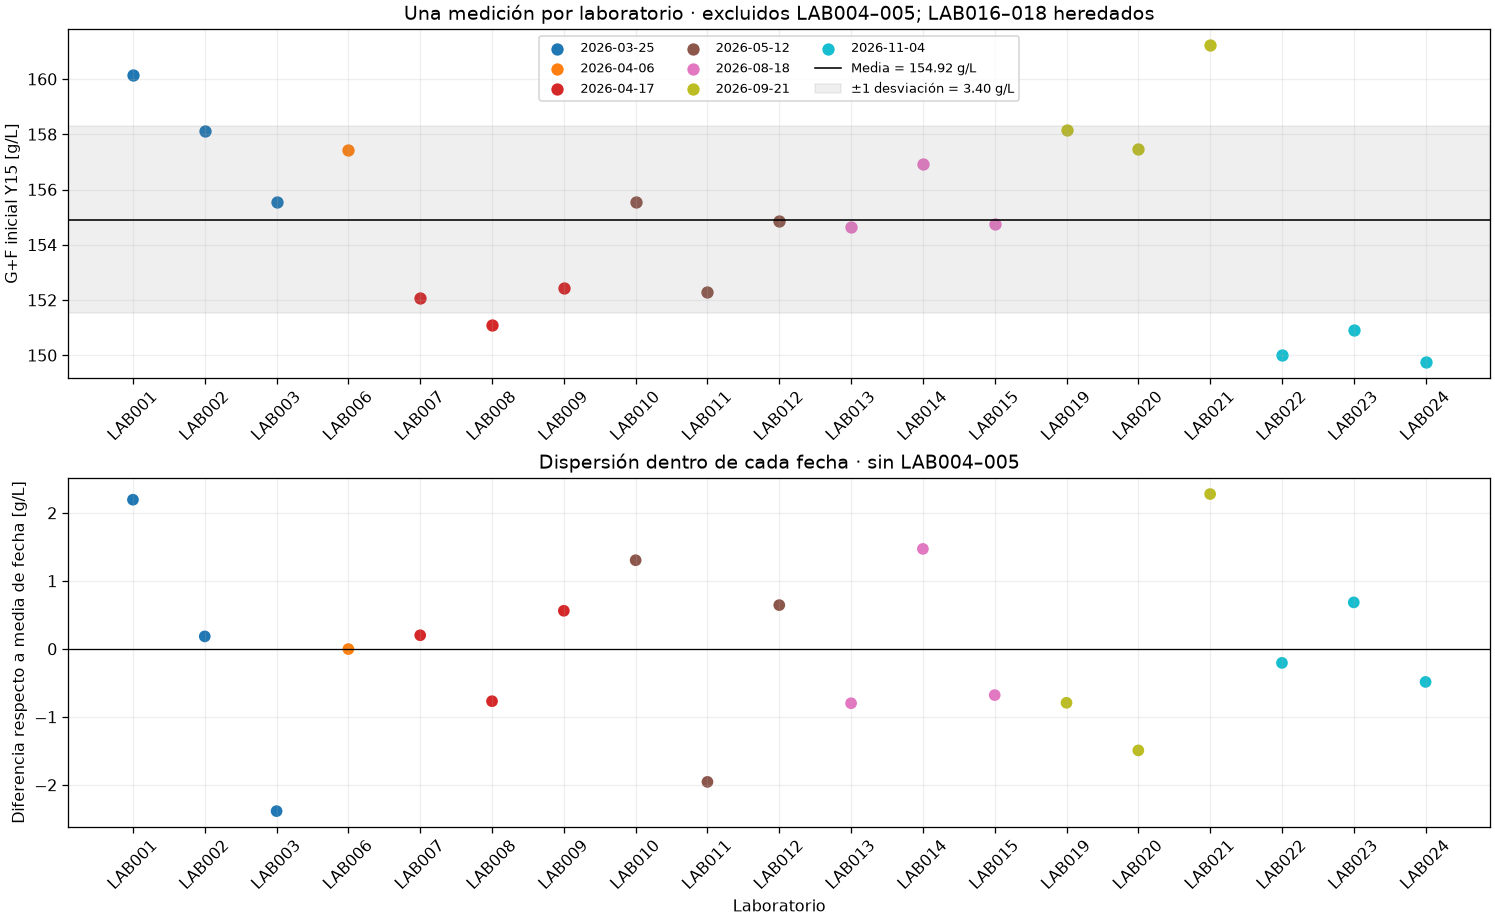

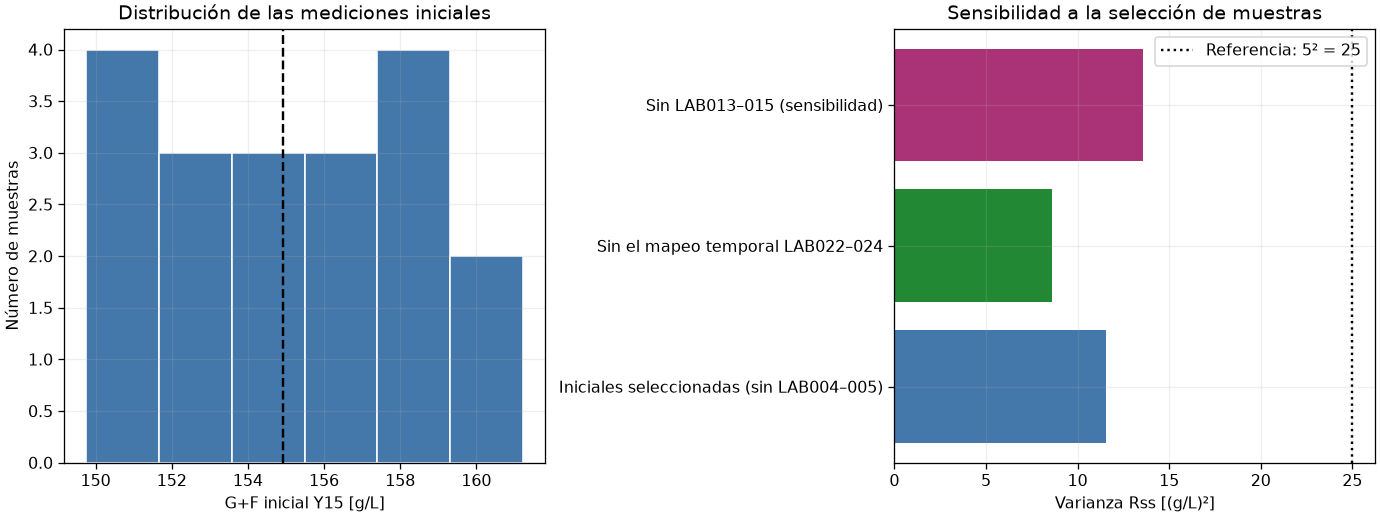

In [4]:
fig,axes=plt.subplots(2,1,figsize=(13,8),layout='constrained')
colors=plt.cm.tab10(np.linspace(0,1,len(groups)))
palette=dict(zip(groups.index,colors))
for date,frame in initials.groupby('fecha_grupo'):
    axes[0].scatter(frame.index,frame.S_g_L,s=45,color=palette[date],label=date)
mean=initials.S_g_L.mean();sd=initials.S_g_L.std(ddof=1)
axes[0].axhline(mean,color='black',lw=1,label=f'Media = {mean:.2f} g/L')
axes[0].axhspan(mean-sd,mean+sd,color='gray',alpha=.12,label=f'±1 desviación = {sd:.2f} g/L')
axes[0].set(xticks=initials.index,xticklabels=initials.LAB,ylabel='G+F inicial Y15 [g/L]',title='Una medición por laboratorio · excluidos LAB004–005; LAB016–018 heredados')
axes[0].tick_params(axis='x',rotation=45);axes[0].legend(ncol=3,fontsize=8)
axes[1].scatter(initials.index,centered,s=40,color=[palette[d] for d in initials.fecha_grupo])
axes[1].axhline(0,color='black',lw=.8)
axes[1].set(xticks=initials.index,xticklabels=initials.LAB,ylabel='Diferencia respecto a media de fecha [g/L]',xlabel='Laboratorio',title='Dispersión dentro de cada fecha · sin LAB004–005')
axes[1].tick_params(axis='x',rotation=45)
for ax in axes:ax.grid(alpha=.2)
plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
axes[0].hist(initials.S_g_L,bins='auto',edgecolor='white',color='#4477AA')
axes[0].axvline(mean,color='black',ls='--')
axes[0].set(xlabel='G+F inicial Y15 [g/L]',ylabel='Número de muestras',title='Distribución de las mediciones iniciales')
axes[1].barh(summary.index,summary.Rss_g2_L2,color=['#4477AA','#228833','#AA3377'])
axes[1].axvline(25,color='black',ls=':',label='Referencia: 5² = 25')
axes[1].set(xlabel='Varianza Rss [(g/L)²]',title='Sensibilidad a la selección de muestras');axes[1].legend()
for ax in axes:ax.grid(alpha=.2)
plt.show()

In [5]:
all_result=summary.iloc[0];mapped=summary.iloc[1]
display(Markdown(f"""## Resultado y alcance para Rss

Se encuentran **{len(initials)} mediciones iniciales** de LAB001–003, LAB006–015 y LAB019–024. LAB004 y LAB005 se excluyen por indicación del usuario. LAB016–018 no añaden réplicas propias: sus condiciones iniciales químicas son heredadas.

Con las iniciales seleccionadas, sin LAB004 y LAB005, la media es **{all_result.media_g_L:.3f} g/L**, la desviación estándar de una medición individual es **{all_result.desviacion_g_L:.3f} g/L** y la estimación empírica es **Rss = {all_result.Rss_g2_L2:.3f} (g/L)²**. El rango observado es {all_result.minimo_g_L:.2f}–{all_result.maximo_g_L:.2f} g/L. Frente al supuesto anterior de 5 g/L, la nueva varianza representa {all_result.Rss_g2_L2/25:.3f} veces 25 (g/L)².

La tabla por fechas y la influencia de cada laboratorio permiten ver si unos pocos registros dominan la dispersión. Al retirar adicionalmente las tres correspondencias temporales de LAB022–024, por sensibilidad, la desviación resulta **{mapped.desviacion_g_L:.3f} g/L** y Rss **{mapped.Rss_g2_L2:.3f} (g/L)²**. No se retiran automáticamente del resultado principal. La anomalía de fermentación de LAB022 tampoco es motivo para descartar su azúcar inicial por sí sola.


La desviación agrupada dentro de fecha es **{np.sqrt(within_variance):.3f} g/L**, con varianza **{within_variance:.3f} (g/L)²**. No es repetibilidad pura: cada laboratorio aporta una muestra distinta y podrían compartir preparación o errores de campaña. Es una comparación con la dispersión global, no una cifra instrumental certificada. Las fechas de las planillas antiguas no siempre son las fechas de análisis, y las diferencias documentadas de lote no se interpretan automáticamente como cambios de mosto, dada la información aportada por el usuario.

**Propuesta:** usar la varianza de las muestras seleccionadas como candidato empírico para la incertidumbre de una medición Y15 individual de mosto inicial, conservando documentadas las diferencias entre campañas y la correspondencia temporal de LAB022–024. No atribuir toda esa varianza al instrumento ni confundirla con incertidumbre de la media. No se ha estimado sesgo respecto a una referencia certificada.

Estos datos cubren concentraciones iniciales altas. No determinan si la incertidumbre es constante, relativa o dependiente de dilución cerca de azúcar cero. Tampoco estiman incertidumbre de densidad ni justifican cambiar Q. Una R más fundamentada no resuelve por sí sola una covarianza de estado demasiado pequeña. **El EKF no se modifica en este análisis.**
"""))

for path,digest in source_hashes.items():assert hashlib.sha256(path.read_bytes()).hexdigest()==digest
display(pd.DataFrame([dict(archivo=str(p.relative_to(ROOT)),sha256=d) for p,d in source_hashes.items()]))
print('Verificado: fuentes intactas, muestras únicas, sin sustitución por densidad, sin condiciones heredadas como réplicas y sin cambios al EKF.')

Verificado: fuentes intactas, muestras únicas, sin sustitución por densidad, sin condiciones heredadas como réplicas y sin cambios al EKF.


## Resultado y alcance para Rss

Se encuentran **19 mediciones iniciales** de LAB001–003, LAB006–015 y LAB019–024. LAB004 y LAB005 se excluyen por indicación del usuario. LAB016–018 no añaden réplicas propias: sus condiciones iniciales químicas son heredadas.

Con las iniciales seleccionadas, sin LAB004 y LAB005, la media es **154.919 g/L**, la desviación estándar de una medición individual es **3.400 g/L** y la estimación empírica es **Rss = 11.560 (g/L)²**. El rango observado es 149.75–161.23 g/L. Frente al supuesto anterior de 5 g/L, la nueva varianza representa 0.462 veces 25 (g/L)².

La tabla por fechas y la influencia de cada laboratorio permiten ver si unos pocos registros dominan la dispersión. Al retirar adicionalmente las tres correspondencias temporales de LAB022–024, por sensibilidad, la desviación resulta **2.934 g/L** y Rss **8.608 (g/L)²**. No se retiran automáticamente del resultado principal. La anomalía de fermentación de LAB022 tampoco es motivo para descartar su azúcar inicial por sí sola.


La desviación agrupada dentro de fecha es **1.567 g/L**, con varianza **2.457 (g/L)²**. No es repetibilidad pura: cada laboratorio aporta una muestra distinta y podrían compartir preparación o errores de campaña. Es una comparación con la dispersión global, no una cifra instrumental certificada. Las fechas de las planillas antiguas no siempre son las fechas de análisis, y las diferencias documentadas de lote no se interpretan automáticamente como cambios de mosto, dada la información aportada por el usuario.

**Propuesta:** usar la varianza de las muestras seleccionadas como candidato empírico para la incertidumbre de una medición Y15 individual de mosto inicial, conservando documentadas las diferencias entre campañas y la correspondencia temporal de LAB022–024. No atribuir toda esa varianza al instrumento ni confundirla con incertidumbre de la media. No se ha estimado sesgo respecto a una referencia certificada.

Estos datos cubren concentraciones iniciales altas. No determinan si la incertidumbre es constante, relativa o dependiente de dilución cerca de azúcar cero. Tampoco estiman incertidumbre de densidad ni justifican cambiar Q. Una R más fundamentada no resuelve por sí sola una covarianza de estado demasiado pequeña. **El EKF no se modifica en este análisis.**


,archivo,sha256
0,data\original\natural\lab001_003\Planilla_Maestra_ID_2026_14_07_26.xlsx,80b3bae205b3cd1669f62d7c895d922a08f4e729b0b551192762663d3644fa79
1,data\original\natural\lab004_012\mosto_natural_original.xlsx,26a51838137829f29b135ff4de15b8dd6a829f1a858fbedd841a30c94f601a40
2,data\original\natural\lab013_015\Y15_LAB013-015.csv,aac88839d9b106d7ba59ef15fdc03b9d755d2af0afdbeee95c432d3cfc0bef33
3,data\original\natural\lab016_018\LAB016-018-offline-measurements.xlsx,9efa982ff17f6bc19844d993cd66717d4fba45d0e2b2b683bd11856447dad7ea
4,data\original\natural\lab019_021\Mediciones-Offline-LAB019-021.xlsx,9b05f6c0ffc55929da5124df340296bda0ea3bb22d9dfb9cea2f31c847bda76d
5,data\original\natural\lab019_021\EXPAuto(2026-09-21 12-49).txt,97395acaf3e85a43d80b6106325825e9be634c9fbb27b49f57737ccc0152be68
6,notebooks\preparing_data\lab022_024_data.source.ipynb,aabe7ed071a27c5077173e09b91acef9820094fe6cef971ac620bffb05159c6b
7,data\original\natural\lab022_024\lab022-024MedicionesOffline_estandar.xlsx,1ff147173064e29e2e5a7bcf412cfd17087c50508f437fa32c8c1210f65f30c5
8,data\original\natural\lab022_024\EXPAuto(2026-11-02 11-57).txt,e41ace58c16acae885298f83c4420132cd78dd511d1b6ce7f5fbf8252119f1e3


## Escenario hipotético · LAB022–024

Se mantiene la selección de 19 mediciones, con LAB004 y LAB005 excluidos. En una copia independiente del azúcar total se sustituyen únicamente LAB022 por 155,5 g/L, LAB023 por 154,5 g/L y LAB024 por 154,0 g/L. Son valores propuestos para estudiar sensibilidad, no nuevas mediciones ni correcciones de las fuentes. No se supone cómo se repartiría ese total entre glucosa y fructosa.

Se compara la desviación estándar muestral y su cuadrado, Rss, con las mediciones originales seleccionadas. El resultado principal anterior se conserva. No se modifica el EKF.

In [6]:
original_snapshot=initials.copy(deep=True)
hypothetical=initials[['LAB','S_g_L']].copy(deep=True)
proposed={'LAB022':155.5,'LAB023':154.5,'LAB024':154.0}
mask=hypothetical.LAB.isin(proposed)
assert mask.sum()==3 and len(hypothetical)==19
hypothetical.loc[mask,'S_g_L']=hypothetical.loc[mask,'LAB'].map(proposed)
pd.testing.assert_frame_equal(initials,original_snapshot)
np.testing.assert_array_equal(hypothetical.loc[~mask,'S_g_L'],initials.loc[~mask,'S_g_L'])

scenario_values=initials[['LAB','S_g_L']].rename(columns={'S_g_L':'Original_g_L'}).merge(
    hypothetical.rename(columns={'S_g_L':'Hipotetico_g_L'}),on='LAB',validate='one_to_one')
scenario_values['Diferencia_g_L']=scenario_values.Hipotetico_g_L-scenario_values.Original_g_L
display(scenario_values.loc[scenario_values.LAB.isin(proposed)])
scenario_summary=pd.DataFrame([
    describe(initials,'Original (19 mediciones seleccionadas)'),
    describe(hypothetical,'Hipotético (solo LAB022–024 sustituidos)')
]).set_index('Conjunto')
display(scenario_summary.round(6))
baseline=scenario_summary.iloc[0];alternative=scenario_summary.iloc[1]
scenario_change=pd.DataFrame({
    'Cambio absoluto':alternative-baseline,
    'Cambio porcentual':100*(alternative/baseline-1)
}).loc[['media_g_L','desviacion_g_L','Rss_g2_L2']]
display(scenario_change.round(6))


,LAB,Original_g_L,Hipotetico_g_L,Diferencia_g_L
16,LAB022,150.03,155.5,5.47
17,LAB023,150.92,154.5,3.58
18,LAB024,149.75,154.0,4.25


,n,media_g_L,desviacion_g_L,Rss_g2_L2,minimo_g_L,maximo_g_L,coeficiente_variacion_pct
Conjunto,,,,,,,
Original (19 mediciones seleccionadas),19,154.918947,3.400039,11.560265,149.75,161.23,2.194721
Hipotético (solo LAB022–024 sustituidos),19,155.618947,2.723570,7.417832,151.10,161.23,1.750153


,Cambio absoluto,Cambio porcentual
media_g_L,0.700000,0.451849
desviacion_g_L,-0.676469,-19.895927
Rss_g2_L2,-4.142433,-35.833375


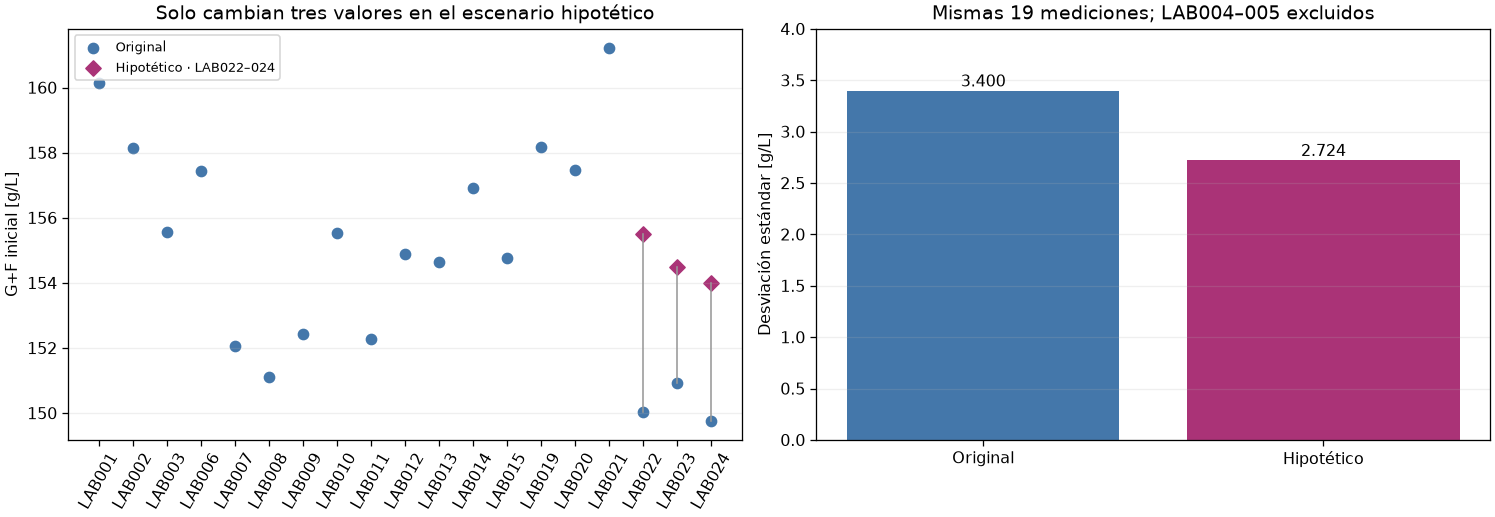

In [7]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5),layout='constrained')
x=np.arange(len(initials))
axes[0].scatter(x,initials.S_g_L,color='#4477AA',s=40,label='Original')
for lab in proposed:
    i=int(np.flatnonzero(initials.LAB.eq(lab))[0])
    axes[0].plot([i,i],[initials.S_g_L.iloc[i],hypothetical.S_g_L.iloc[i]],color='#999999',lw=1)
axes[0].scatter(x[mask],hypothetical.loc[mask,'S_g_L'],color='#AA3377',marker='D',s=45,label='Hipotético · LAB022–024')
axes[0].set(xticks=x,xticklabels=initials.LAB,ylabel='G+F inicial [g/L]',title='Solo cambian tres valores en el escenario hipotético')
axes[0].tick_params(axis='x',rotation=60);axes[0].legend(fontsize=8)
axes[1].bar(['Original','Hipotético'],scenario_summary.desviacion_g_L,color=['#4477AA','#AA3377'])
for i,value in enumerate(scenario_summary.desviacion_g_L):axes[1].text(i,value+.04,f'{value:.3f}',ha='center')
axes[1].set(ylabel='Desviación estándar [g/L]',ylim=(0,4),title='Mismas 19 mediciones; LAB004–005 excluidos')
for ax in axes:ax.grid(axis='y',alpha=.2)
plt.show()


In [8]:
display(Markdown(f"""### Interpretación del escenario hipotético

La desviación estándar cambia de **{baseline.desviacion_g_L:.3f} a {alternative.desviacion_g_L:.3f} g/L**: disminuye {baseline.desviacion_g_L-alternative.desviacion_g_L:.3f} g/L (**{100*(1-alternative.desviacion_g_L/baseline.desviacion_g_L):.2f} %**). La varianza Rss pasa de **{baseline.Rss_g2_L2:.3f} a {alternative.Rss_g2_L2:.3f} (g/L)²**, una reducción de **{100*(1-alternative.Rss_g2_L2/baseline.Rss_g2_L2):.2f} %**. La media pasa de {baseline.media_g_L:.3f} a {alternative.media_g_L:.3f} g/L.

Los tres valores propuestos quedan más cerca del centro de las otras mediciones y reducen la dispersión. Esto muestra la sensibilidad de Rss a esas condiciones iniciales. **No constituye evidencia para reemplazar las mediciones originales ni para adoptar la varianza hipotética en el EKF.** La estimación basada en los datos originales seleccionados continúa siendo {baseline.Rss_g2_L2:.3f} (g/L)². Se mantiene la limitación de que son concentraciones iniciales altas.
"""))
pd.testing.assert_frame_equal(initials,original_snapshot)
for path,digest in source_hashes.items():assert hashlib.sha256(path.read_bytes()).hexdigest()==digest
print('Verificado: escenario sobre copia, 3 sustituciones, 19 muestras, originales intactos y fuentes intactas.')


Verificado: escenario sobre copia, 3 sustituciones, 19 muestras, originales intactos y fuentes intactas.


### Interpretación del escenario hipotético

La desviación estándar cambia de **3.400 a 2.724 g/L**: disminuye 0.676 g/L (**19.90 %**). La varianza Rss pasa de **11.560 a 7.418 (g/L)²**, una reducción de **35.83 %**. La media pasa de 154.919 a 155.619 g/L.

Los tres valores propuestos quedan más cerca del centro de las otras mediciones y reducen la dispersión. Esto muestra la sensibilidad de Rss a esas condiciones iniciales. **No constituye evidencia para reemplazar las mediciones originales ni para adoptar la varianza hipotética en el EKF.** La estimación basada en los datos originales seleccionados continúa siendo 11.560 (g/L)². Se mantiene la limitación de que son concentraciones iniciales altas.
